# 7 · Eksik modalite analizi (Kriter 4)

**Sorular:** Her pencerede hangi sensörler var? Eksiklik rastgele mi, bir düzeni var mı? Eksik veriyle ne yapıyoruz?

**Strateji:** Hiçbir pencere silinmiyor. Her kanal için bir **maske** (var = 1, yok = 0) tutuluyor; model eksik kanalı bu
işaretle bilerek yok sayıyor. Projenin adındaki "eksik modaliteye dayanıklı" buradan.

**Kurulum hücresi.** Önce bunu çalıştır (ya da Run → Run All). Kütüphaneleri, projenin `src/` kodlarını ve
etiketleri yükler; sonraki hücreler buradaki isimleri kullanır.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))           # projenin kendi kodları (src/) buradan çağrılır
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from build import OUT, INTERIM, ENV_COLS, HOMES, hubs_of
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
CLS = ["0 kişi", "1 kişi", "2+ kişi"]; RENK = ["#2A78D6", "#EB6834", "#1BAF7A"]   # bütün grafiklerde aynı renkler
LAB = {h: pd.read_parquet(OUT / h / "labels.parquet") for h in HOMES}           # etiketler (her ev için 10 sn ızgara)
print("evler:", HOMES, "| toplam pencere:", sum(map(len, LAB.values())))

evler: ['H1', 'H2', 'H3', 'H4', 'H5', 'H6'] | toplam pencere: 1311925


In [2]:
def maskeler(h):
    """Bir ev için hub × pencere maskeleri: görüntü, ses, ortam (5 sensörün hepsi dolu, temizlik + doldurma sonrası)."""
    from clean import clean_env, fill_short_gaps
    hubs = hubs_of(h)
    img = np.stack([pd.read_parquet(OUT / h / f"{b}_img.parquet")["offset"].to_numpy() >= 0 for b in hubs])
    aud = np.stack([pd.read_parquet(OUT / h / f"{b}_aud.parquet")["aud_ok"].to_numpy() for b in hubs])
    env = np.stack([~np.isnan(fill_short_gaps(clean_env(np.load(OUT / h / f"{b}_env.npy"), b, ENV_COLS))).any(1) for b in hubs])
    return hubs, img, aud, env
M = {h: maskeler(h) for h in HOMES}

## 7.1 Hub bazında: hangi modalite ne kadar var?

In [3]:
R = []
for h, (hubs, img, aud, env) in M.items():
    for k, b in enumerate(hubs):
        R.append({"ev-hub": f"{h}-{b}", "görüntü %": 100 * img[k].mean(), "ses %": 100 * aud[k].mean(),
                  "ortam (tam) %": 100 * env[k].mean(), "üçü birden %": 100 * (img[k] & aud[k] & env[k]).mean()})
R = pd.DataFrame(R).set_index("ev-hub").round(1)
display(R.mean().round(1).rename("ortalama").to_frame().T); R

,görüntü %,ses %,ortam (tam) %,üçü birden %
ortalama,65.6,87.4,77.8,46.6


,görüntü %,ses %,ortam (tam) %,üçü birden %
ev-hub,,,,
H1-RS1,54.8,94.2,99.6,52.0
H1-RS2,99.4,96.7,99.8,96.3
H1-RS3,55.6,94.5,99.7,52.7
H1-RS4,51.5,95.5,99.7,49.2
H1-RS5,45.8,95.7,0.0,0.0
H2-RS1,69.6,90.3,97.9,62.5
H2-RS2,76.4,89.3,96.1,66.1
H2-RS4,100.0,91.6,96.7,88.6
H2-RS5,76.8,91.8,0.0,0.0


RS5 kutularında "ortam (tam)" düşük çünkü nem kanalı çıkarıldı (Notebook 6); diğer dört sensör duruyor ve ortam maskesi
sensör bazında tutuluyor. Üçünün birden olduğu pencere yaklaşık yarı yarıya.

## 7.2 Pencere bazında: evde en az bir kutuda hangi modalite var?

In [4]:
R2 = []
for h, (hubs, img, aud, env) in M.items():
    R2.append({"Ev": h, "en az bir kare %": 100 * img.any(0).mean(), "en az bir ses %": 100 * aud.any(0).mean(),
               "en az bir ortam %": 100 * env.any(0).mean(), "hiç kare yok %": 100 * (~img.any(0)).mean(),
               "hiçbir şey yok %": 100 * (~(img | aud | env).any(0)).mean()})
pd.DataFrame(R2).set_index("Ev").round(1)

,en az bir kare %,en az bir ses %,en az bir ortam %,hiç kare yok %,hiçbir şey yok %
Ev,,,,,
H1,99.5,100.0,100.0,0.5,0.0
H2,100.0,94.4,99.7,0.0,0.0
H3,72.1,100.0,99.9,27.9,0.0
H4,66.1,100.0,100.0,33.9,0.0
H5,70.2,100.0,99.7,29.8,0.0
H6,63.3,99.5,100.0,36.7,0.0


Ev düzeyinde bakınca neredeyse her pencerede en az bir sensör var; tamamen boş pencere yok denecek kadar az. Eksiklik
modaliteye özgü: görüntü en çok eksik olan.

## 7.3 Eksiklik rastgele mi? Günün saatine göre

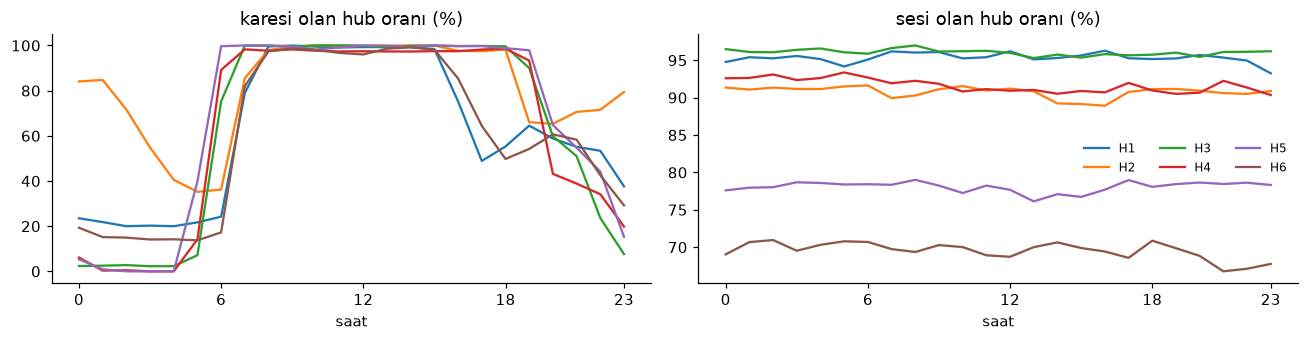

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
for h, (hubs, img, aud, env) in M.items():
    hr = LAB[h]["ts"].dt.hour.to_numpy()
    ax[0].plot(pd.Series(img.mean(0)).groupby(hr).mean() * 100, label=h)
    ax[1].plot(pd.Series(aud.mean(0)).groupby(hr).mean() * 100, label=h)
ax[0].set_title("karesi olan hub oranı (%)"); ax[1].set_title("sesi olan hub oranı (%)")
for a in ax: a.set_xlabel("saat"); a.set_xticks([0, 6, 12, 18, 23])
ax[1].legend(ncol=3, frameon=False, fontsize=8); plt.tight_layout(); plt.show()

**Görüntü eksikliği rastgele değil:** gece (00–06) kare oranı çöküyor; yazarlar ışık kapalıyken kareleri silmiş. Ses ise
gün boyu düz: eksikliği saatten bağımsız (donanım kesintisi).

## 7.4 Kısayol riski: "kare yoksa kalabalık"

Gece kare yok ve gece çok kişilik evlerde herkes evde. Model bu iki şeyi birbirine bağlayabilir.

In [6]:
R3 = []
for h, (hubs, img, aud, env) in M.items():
    g = LAB[h]; n = (g["ts"].dt.hour < 6).to_numpy()
    R3.append({"Ev": h, "gece karesiz hub %": 100 * (~img[:, n]).mean(), "gece 2+ payı %": 100 * (g["cls"].to_numpy()[n] == 2).mean(),
               "gündüz karesiz hub %": 100 * (~img[:, ~n]).mean(), "gündüz 2+ payı %": 100 * (g["cls"].to_numpy()[~n] == 2).mean()})
pd.DataFrame(R3).set_index("Ev").round(1)

,gece karesiz hub %,gece 2+ payı %,gündüz karesiz hub %,gündüz 2+ payı %
Ev,,,,
H1,78.8,86.4,25.0,50.3
H2,38.2,0.0,13.0,0.5
H3,96.8,88.6,16.4,50.3
H4,96.5,60.7,17.1,22.8
H5,92.3,40.0,12.7,36.9
H6,84.8,0.0,26.3,0.0


**Okuma:** H1'de gece kutuların çoğunda kare yok ve pencerelerin çoğu 2+. H6'da da gece kare yok ama 2+ hiç yok. Model
H1 gibi evlerden "kare yoksa 2+" kuralını ezberlerse H6'da her gece yanılır: insanı değil karanlığı öğrenmiş olur.
**Önlem:** maske + eğitimde rastgele modalite düşürme (modality dropout) + ev bazlı test (H6 test evi olduğunda bu hata görünür).

## 7.5 Model bu maskeyi nasıl görüyor? (gerçek örnek)

In [7]:
from dataset import window
w = window("H6", 100_000)       # 4 hub'lı ev, BS2'de mikrofon yok
print("hub yuvaları :", w["hubs"])
print("görüntü maskesi:", w["mask_img"].astype(int), "| ses maskesi:", w["mask_aud"].astype(int))
print("ortam maskesi (hub × sensör):"); print(w["mask_env"].astype(int))
print("etiket:", w["y"], f"({w['number']} kişi)")

hub yuvaları : ['BS2', 'BS3', 'BS4', 'BS5', None]
görüntü maskesi: [1 1 1 1 0] | ses maskesi: [0 1 0 1 0]
ortam maskesi (hub × sensör):
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 0 0 0]]
etiket: 0 (0 kişi)


5. yuva boş (H6'da 4 kutu var), BS2'nin sesi yok → ses maskesinde 0. Eksik kanalın değeri 0 yazılıyor ama model 0'ın
"gerçekten sıfır" mı "yok" mu olduğunu maskeden anlıyor.